# 01. Data: cell lines, drugs, expression and a batch effect

**Question for the project:** can a cancer cell line's gene expression predict how strongly it
responds to a drug, beyond what its cancer type already tells us? And which genes carry the signal?

| Source | Content |
|---|---|
| GDSC2 release 8.5 (Wellcome Sanger Institute) | fitted dose-response curves: 295 drugs x up to 969 cell lines, CellTiter-Glo viability assay |
| GDSC1 release 8.5 | 402 drugs, older Syto60/resazurin assays; used for the cross-assay test |
| Cell Model Passports | RNA-seq (log2 TPM+1), cell-line annotation (tissue, cancer type), driver mutations |

The response is the **area under the dose-response curve (AUC)** over the screened concentration
range: 1 means no killing at any tested dose, lower means more sensitive.

In [1]:
import sys, warnings, pickle
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from drugresponse import data

In [2]:
E = data.load_expression(); M = data.load_models(); R = data.load_response(); drugs = data.load_drugs()
print(f"expression: {E.shape[0]} cell lines x {E.shape[1]} genes (expressed in >= 10% of lines)")
print(f"GDSC2 response: {R.shape[1]} drugs; cell lines per drug: median {R.notna().sum().median():.0f}")
print(f"drugs screened in >= 300 lines (analysed): {(R.notna().sum() >= 300).sum()}")
M.tissue.value_counts().head(15)

expression: 953 cell lines x 18407 genes (expressed in >= 10% of lines)
GDSC2 response: 295 drugs; cell lines per drug: median 870
drugs screened in >= 300 lines (analysed): 281


tissue
Lung                           174
Haematopoietic and Lymphoid    169
Skin                            58
Central Nervous System          55
Breast                          51
Large Intestine                 48
Head and Neck                   41
Bone                            41
Ovary                           41
Esophagus                       35
Kidney                          33
Pancreas                        31
Peripheral Nervous System       31
Stomach                         28
Bladder                         18
Name: count, dtype: int64

## Response: some drugs barely vary, others split lines sharply

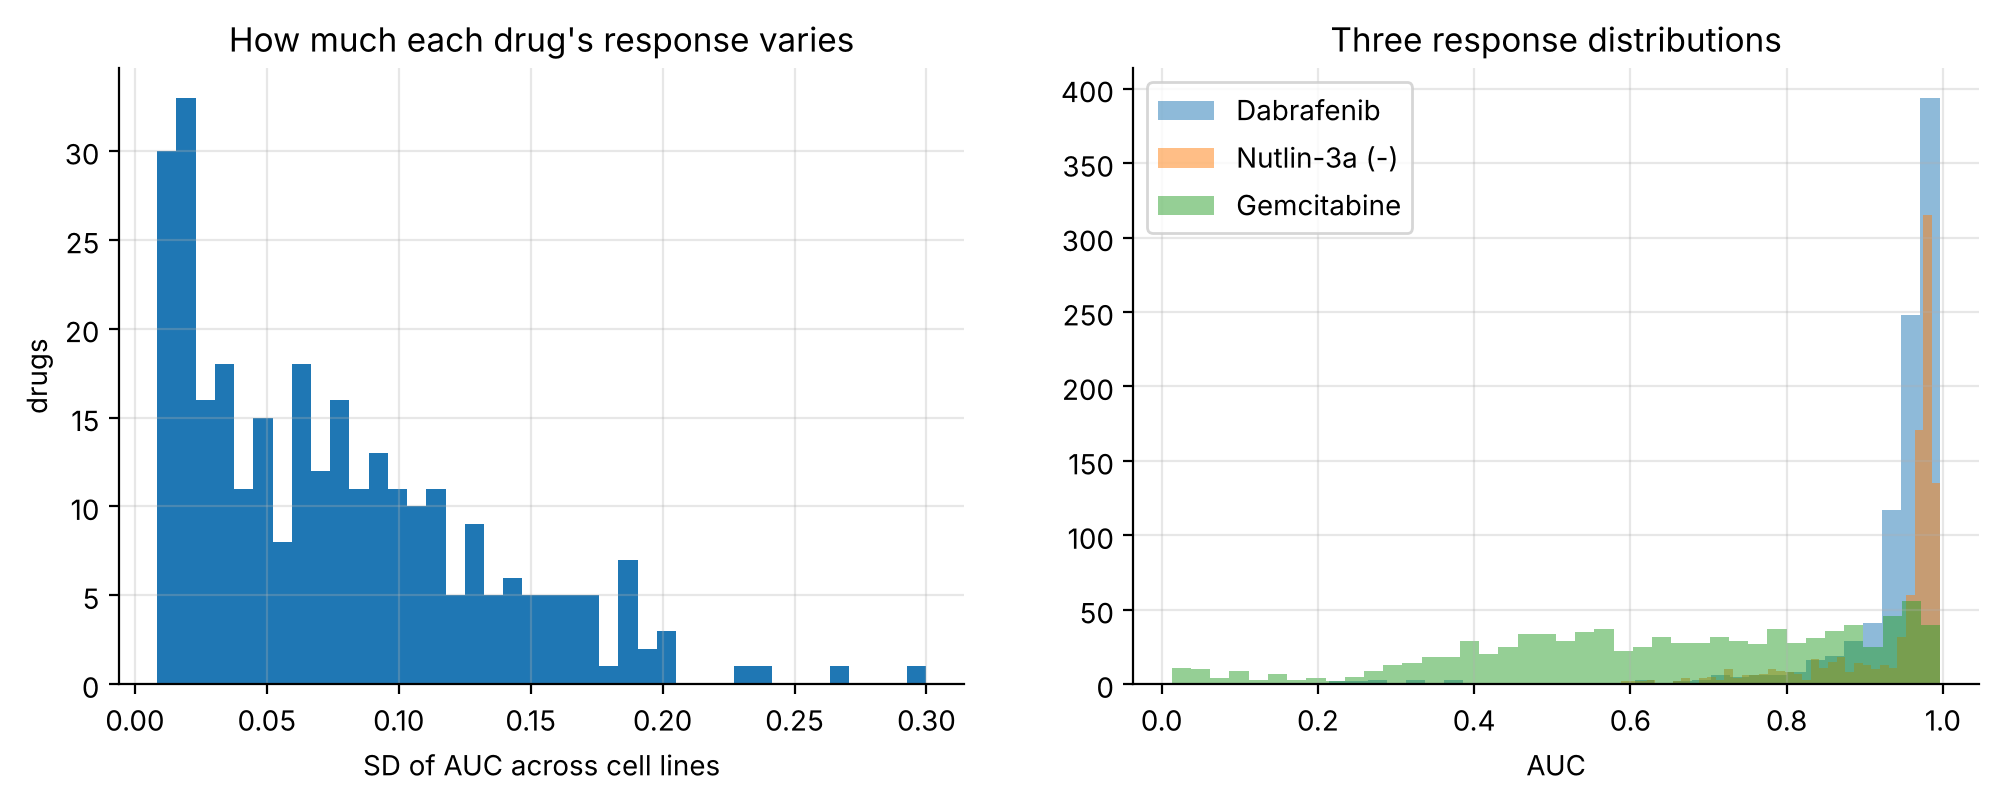

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(drugs.auc_sd, bins=40); ax[0].set(xlabel="SD of AUC across cell lines", ylabel="drugs",
                                             title="How much each drug's response varies")
for name in ["Dabrafenib", "Nutlin-3a (-)", "Gemcitabine"]:
    d = drugs.index[drugs.drug_name == name][0]
    ax[1].hist(R[d].dropna(), bins=40, alpha=0.5, label=name)
ax[1].legend(); ax[1].set(xlabel="AUC", title="Three response distributions");

Dabrafenib (a BRAF inhibitor) splits the lines into a small, very sensitive group (BRAF-mutant
melanoma) and everyone else. Gemcitabine kills most lines, to varying degrees. A drug with almost
no spread has little to predict.

## Cancer type explains a lot

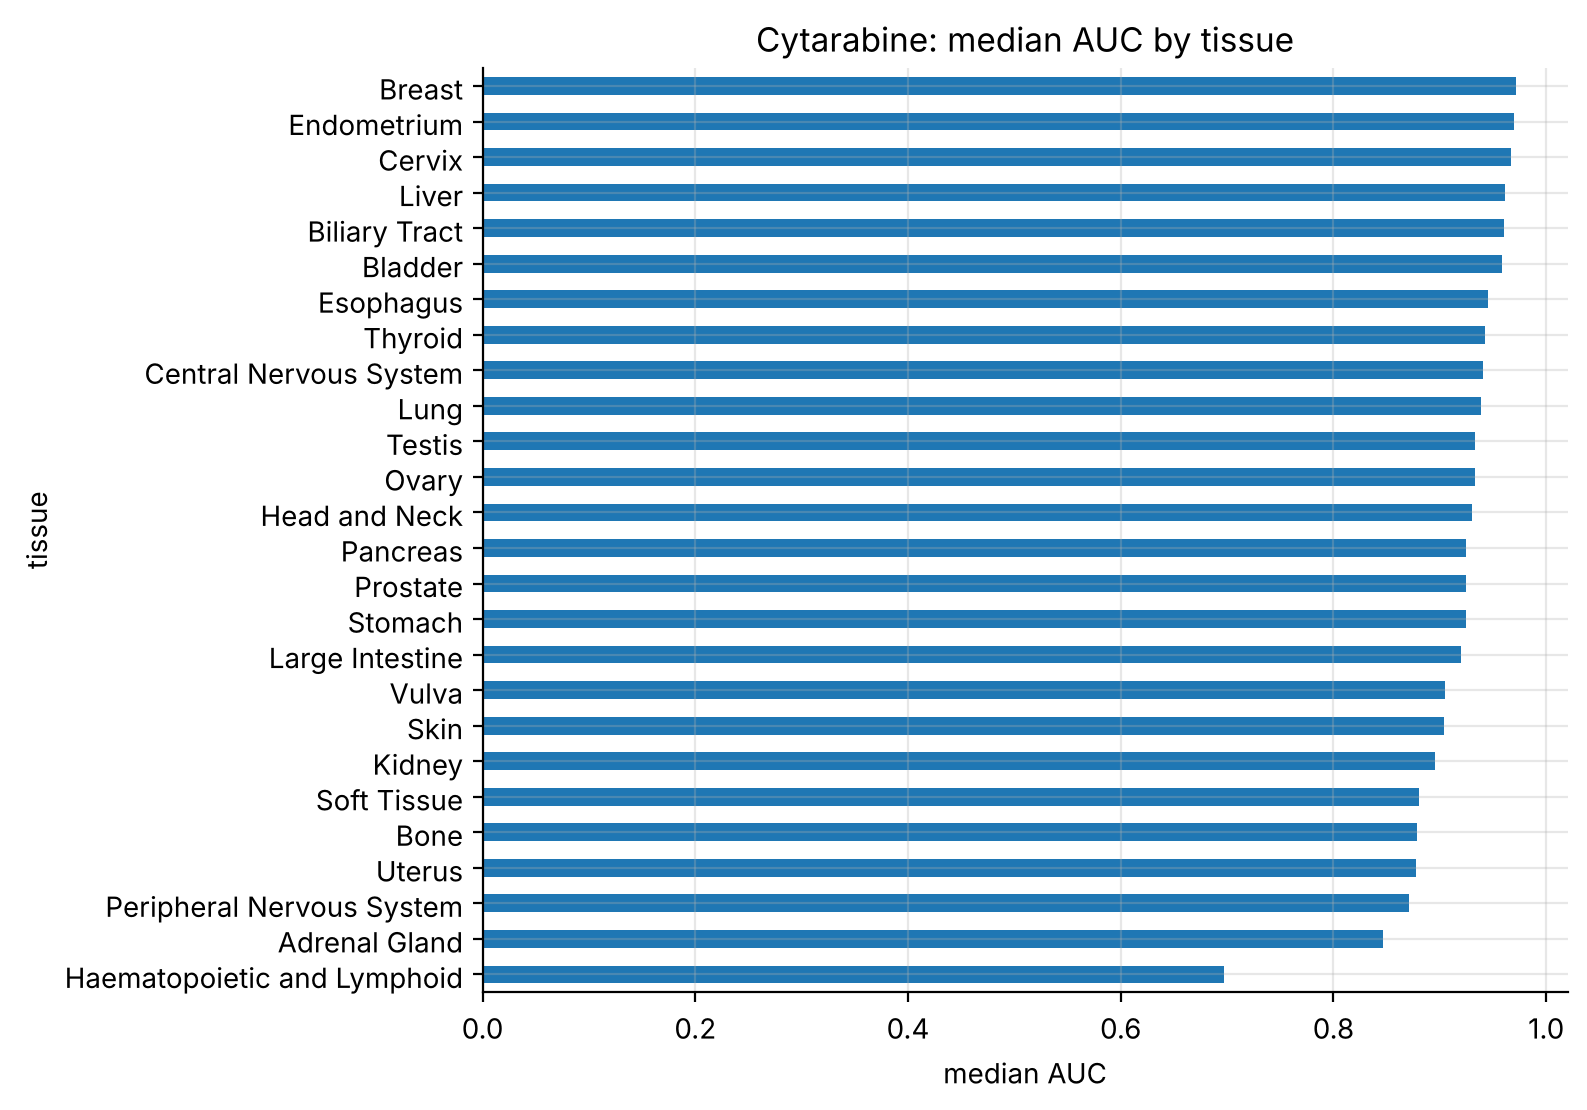

In [4]:
d = drugs.index[drugs.drug_name == "Cytarabine"][0]
by = R[d].groupby(M.tissue.reindex(R.index)).median().dropna().sort_values()
ax = by.plot.barh(figsize=(7, 6)); ax.set(xlabel="median AUC", title="Cytarabine: median AUC by tissue");

## A batch effect in the expression data
550 profiles come from the Broad Institute's pipeline and 403 from Sanger's. Both are on the
log2(TPM + 1) scale, but the source is almost perfectly predictable from the profiles. Each gene's
source effect is estimated controlling for tissue, and subtracted inside each training fold
(`drugresponse.models.Design`; demonstration in learn/06).

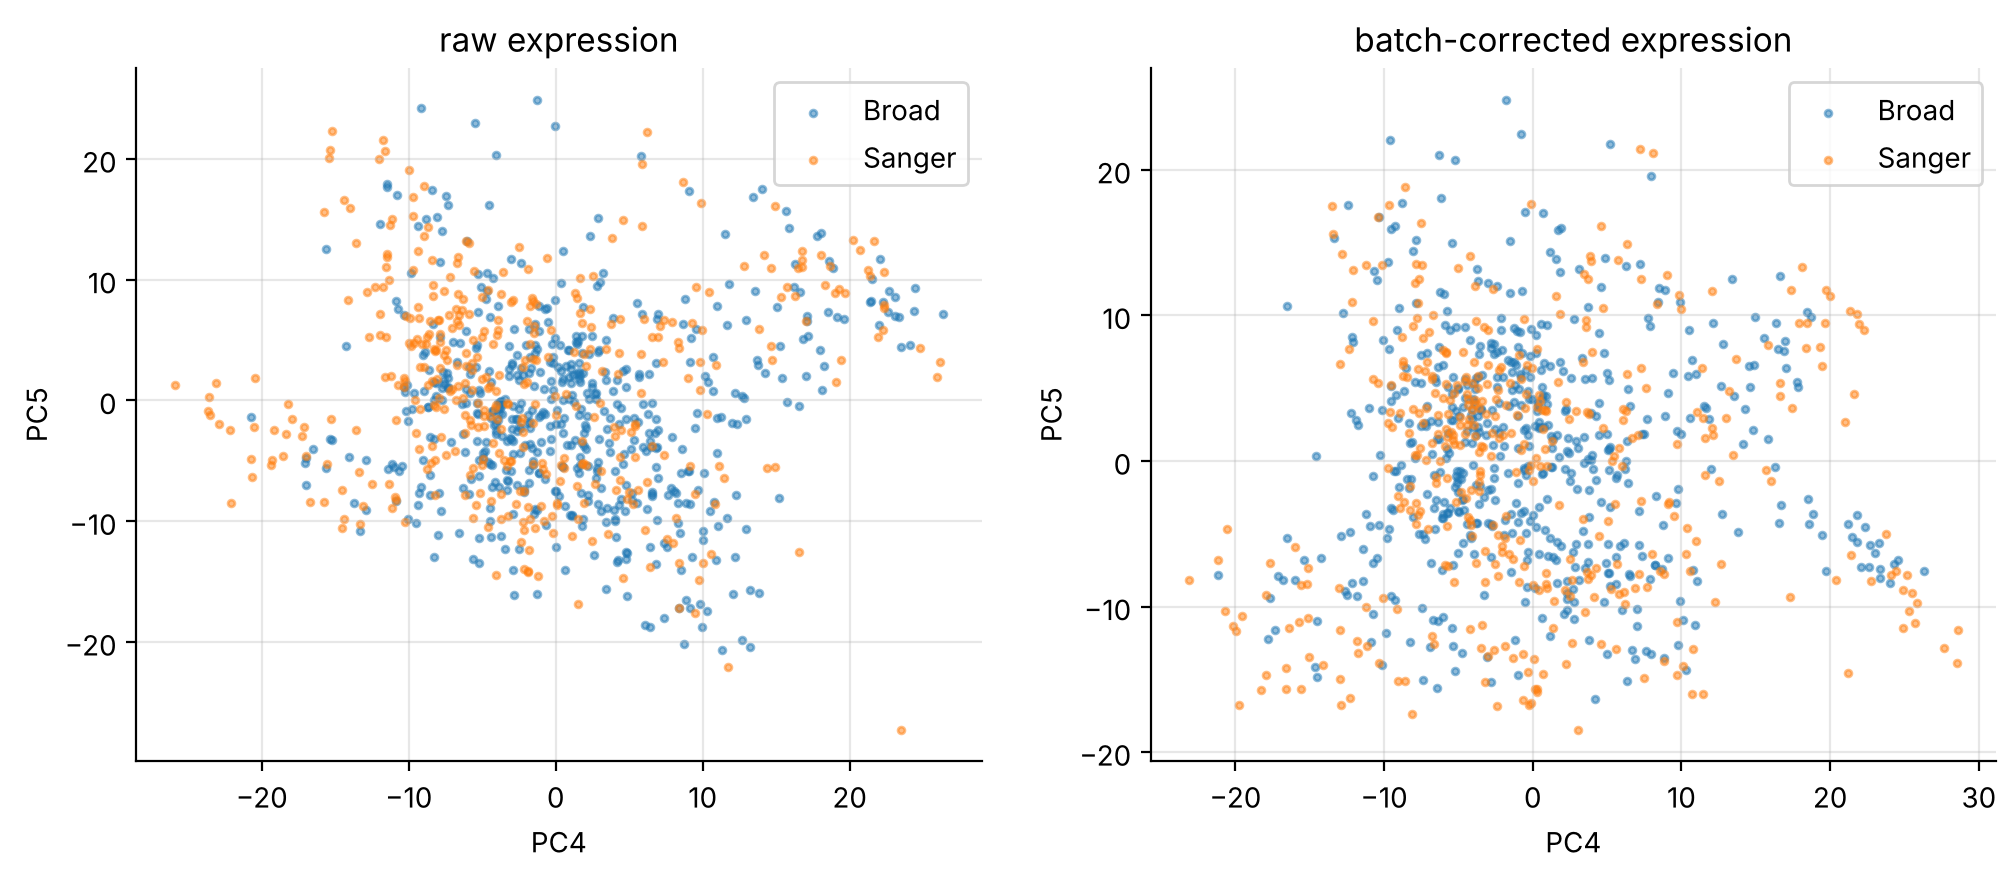

In [5]:
from sklearn.decomposition import PCA
s = (M.reindex(E.index).expression_source == "Sanger").values
from drugresponse.models import Design
d_all = Design(3000).fit(E.values.astype(float), M.reindex(E.index).tissue.values, s)
Zc = d_all.transform(E.values.astype(float), M.reindex(E.index).tissue.values, s)[:, ~d_all.is_tissue()]
Zr = E.values[:, d_all.genes_].astype(float); Zr = (Zr - Zr.mean(0)) / Zr.std(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, Z, title in [(ax[0], Zr, "raw"), (ax[1], Zc, "batch-corrected")]:
    P = PCA(6, random_state=0).fit_transform(Z)
    a.scatter(P[~s, 3], P[~s, 4], s=6, alpha=0.5, label="Broad")
    a.scatter(P[s, 3], P[s, 4], s=6, alpha=0.5, label="Sanger")
    a.set(xlabel="PC4", ylabel="PC5", title=f"{title} expression"); a.legend()